# The no-knowledge regime without its most guessable questions

Under no knowledge a correct answer is a guess. Some questions give their answer away: a reader who never saw
the paragraph still picks the right answer, whatever their eyes do on the screen. Here, how guessable each
question is, from every source of guesses there is, and the L1-trained correctness model scored on KnowQA's
no-knowledge trials with the most guessable quarter of the questions left out. Section 7 sums up what it shows.

**Three sources**, all answering the questions without the paragraph:

* **`guess.tsv`**: Prolific, on the experiment's own version of the questions. About six guesses per
  question, three at each level. It covers the first two of the three article batches.
* **The pilot batches**: an earlier version of the questions. About thirty guesses per question.
* **KnowQA's no-knowledge regime**: the experiment itself. One or two answers per question.

**The most drastic version, on purpose:**

* every pilot question is pooled, however much it changed before the experiment;
* every pilot guess is pooled, including those after the first question of a session, made after reading
  earlier paragraphs of the same article;
* the two levels are pooled: the guesser never sees the paragraph, and OneStop gives a question the same
  answers at both levels;
* KnowQA's own no-knowledge answers are in the pool, so the questions are ranked partly on the outcome the model
  is scored on. Section 5 ranks them without those answers, to see whether it matters.

**The model** is the Study 2 analysis's own (`knowledge_regimes/descriptives.py`): the logistic regression,
fitted once on every L1 trial on the twelve showcase features, then applied to every KnowQA trial. Only the
trials it is scored on change between the runs below; the fit, the coefficients and the predictions do not.
The guessable questions are left out of the test only: the L1 training trials include the same questions, and
stay as they are.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from src.explorations.guessability import no_knowledge as NK
from src.explorations.guessability import pooled as P
from src.explorations.guessability.pooled import QUESTION_KEY, SOURCES

SAVE = True     # writes the figures and their tables to reports/explorations/guessability/
TOP = NK.TOP    # the share of the no-knowledge questions left out, most guessable first
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 120)   # the list of questions left out, in full

## 1. The model's predictions
*`no_knowledge.knowqa_predictions`*

KnowQA's trial table with the regime, session and confidence rating attached, the model fitted on L1, and its
predicted probability of a correct answer added to every trial. The printout says how many feature cells the
model fills with 0 because they are empty (a pupil size exists only where the person fixated).

In [2]:
knowqa = NK.knowqa_predictions()

KnowQA showcase frame: 1885 trials x 201 columns
  participants : 13
  sessions     : 39
  regimes      : {'full knowledge': 640, 'no knowledge': 625, 'partial knowledge': 620}
fitted trial_level_log_reg on 19436 L1 trials, 12 features
  L1 base rate: 0.8407
imputed with fill_value=0.0: 11 cell(s) = 0.049% of the KnowQA feature matrix
    mean_max_fix_pupil_size_z__correct: 11 (0.58% of trials)


## 2. The three sources, matched to the experiment's questions
*`no_knowledge.all_guesses`, `pooled.match_questions`*

Each guessing file is matched to the experiment's own questions: every paragraph it shows to the experiment's
paragraph at the same level, by the words they share, then the questions within a paragraph one-to-one, by how
alike the question and its four answers are. Each question is keyed by `question_key`, its experiment id
without the level (`batch_article_paragraph_question`).

First, how many guesses each source gives and how often they were right. `guess.tsv` and the pilot also have
questions the experiment never asked under no knowledge; from the ranking in section 3 on, only those it did ask
count.

In [3]:
guesses, pairs = NK.all_guesses(knowqa)
display(guesses.groupby("dataset")
               .agg(guesses=("is_correct", "size"), questions=(QUESTION_KEY, "nunique"),
                    participants=("participant", "nunique"), share_correct=("is_correct", "mean"))
               .reindex(list(SOURCES)).round(3))

,guesses,questions,participants,share_correct
dataset,,,,
guess,1940,324,970,0.319
pilot,16263,486,3023,0.376
knowqa,625,337,13,0.371


How alike the matched versions are. `identical` is the same question and answers after case and punctuation;
`match_score` is the mean similarity of the question and the four answers (1 = identical). Every question is
paired however low its score. `correct_was_distractor` is a question whose correct answer in the experiment
was a wrong answer in the file: its guesses there were scored against a different answer key. They are pooled
all the same.

`guess.tsv` is the experiment's version, all but a handful of questions word for word, and no answer key differs.
The pilot is not: under half its questions are identical, and in one (`2_3_4_1`) the answer key changed. There
the pilot's correct answer, "The government", is gone from the final version, and "4,500 volunteers", a wrong
answer in the pilot, became the correct one.

In [4]:
display(pairs.groupby("dataset").agg(
    questions=(QUESTION_KEY, "size"),
    identical=("identical", "sum"),
    correct_answer_same=("correct_answer_same", "sum"),
    correct_was_distractor=("correct_was_distractor", "sum"),
    match_score_below_half=("match_score", lambda s: int((s < 0.5).sum())),
    median_match_score=("match_score", "median"),
).round(3))
display(pairs.loc[pairs["correct_was_distractor"], ["dataset", QUESTION_KEY, "question", "options"]])

,questions,identical,correct_answer_same,correct_was_distractor,match_score_below_half,median_match_score
dataset,,,,,,
guess,324,310,322,0,0,1.00
pilot,486,205,358,1,16,0.98


,dataset,question_key,question,options
545,pilot,2_3_4_1,Who runs the treatment programs for prisoners?,"The government|4,500 volunteers|Gustafsson|Religious organizations"


### How much each question changed
*`pooled.change`*

The words changed between a file's version of a question and the experiment's, over the question and its four
answers, after case and punctuation. A question with its answers runs to about 40 words. Four levels: none
changed (`identical`); one or two (`1-2 words`, such as "more taxes" becoming "additional taxes"); at least one of
the five texts with more than half its words changed (`rewritten`, most often a wrong answer replaced); and
anything between (`reworded`). The cut-offs are a choice, to tell a small edit from a new text. `identical` and
`1-2 words` together are the questions that are *almost the same*.

In [5]:
display(pd.crosstab(pairs["dataset"], pairs["change"]).reindex(columns=P.CHANGE_LEVELS)
          .assign(almost_the_same=lambda t: t["identical"] + t["1-2 words"]))
display(pairs.groupby("dataset")["words_changed"].describe().round(1))

change,identical,1-2 words,reworded,rewritten,almost_the_same
dataset,,,,,
guess,310,13,0,1,323
pilot,205,72,63,146,277


,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
guess,324.0,0.1,0.4,0.0,0.0,0.0,0.0,3.0
pilot,486.0,5.6,9.5,0.0,0.0,1.0,7.0,57.0


## 3. How guessable each question is
*`no_knowledge.guessability`, `no_knowledge.source_agreement`, `pooled.carry_over`, `no_knowledge.flag_most_guessable`*

A question's guessability is its share of right guesses over all three sources pooled, every guess counting once,
so the pilot carries most of the weight. Before trusting the pool, how far the sources agree on which questions
are easy to guess: the Spearman correlation of their shares, over the questions both have. With six or two
guesses per question the correlation is held down by noise, so read it as a floor.

In [6]:
items = NK.guessability(guesses)
display(NK.source_agreement(items).round(3))

,source_a,source_b,questions,median_guesses_a,median_guesses_b,spearman_r
0,guess,pilot,324,6.0,31.0,0.386
1,guess,knowqa,223,6.0,2.0,0.276
2,pilot,knowqa,337,32.0,2.0,0.288


### Does a question's guessability survive the pilot's edits?

The same agreement between the pilot and `guess.tsv`, split by how much the pilot's version differs from the
experiment's. `guess.tsv` asks the experiment's own version, so the `identical` row is the agreement to expect
when nothing changed, noise included.

* **Almost the same** (`identical`, `1-2 words`): the two agree as well as they do when nothing changed. These
  are the same item in both.
* **Reworded or rewritten**: the agreement falls to near nothing. These are different items: what made the
  pilot's version easy or hard to guess did not survive the edit.
* **The rewritten questions were the easy ones.** In the pilot they were guessed right far more often than the
  questions left alone; in the experiment's version, much less so. That looks like the pilot's guessing results
  were used to revise the questions that gave their answer away. It is an inference from these numbers, not
  something the data records.

In [7]:
display(P.carry_over(items, pairs).round(3))

,pilot_change,questions,mean_share_pilot,mean_share_guess,spearman_r
0,identical,137,0.346,0.312,0.474
1,1-2 words,52,0.324,0.312,0.624
2,reworded,46,0.360,0.288,0.023
3,rewritten,89,0.448,0.351,0.244
4,all,324,0.373,0.319,0.386


### The ranking

The questions answered under no knowledge, ranked by their pooled share. The top quarter is left out; ties at
the cut all go out, so it can be slightly more than a quarter. The ranking is over the test's own questions, so
the quarter is of what the model is scored on.

337 questions answered under no knowledge; cut at a pooled share of 0.500: 88 left out (26.1%)


,n_guesses,n_guess,n_pilot,n_knowqa
count,337.0,337.0,337.0,337.0
mean,39.1,4.0,33.3,1.9
std,2.5,2.8,4.5,0.4
min,34.0,0.0,26.0,1.0
25%,37.0,0.0,30.0,2.0
50%,39.0,6.0,32.0,2.0
75%,40.0,6.0,37.0,2.0
max,51.0,6.0,49.0,2.0


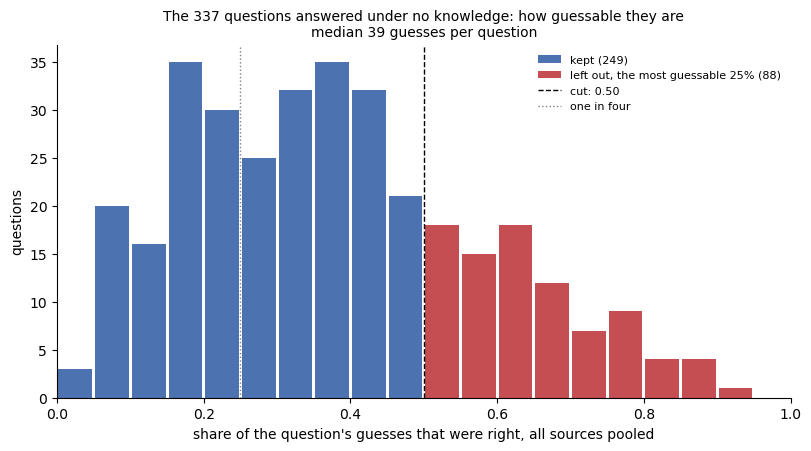

In [8]:
flagged, cut = NK.flag_most_guessable(items, knowqa, top=TOP)
n_out = int(flagged["most_guessable"].sum())
print(f"{len(flagged)} questions answered under no knowledge; cut at a pooled share of {cut:.3f}: "
      f"{n_out} left out ({n_out / len(flagged):.1%})")
display(flagged[["n_guesses", "n_guess", "n_pilot", "n_knowqa"]].describe().round(1))
NK.plot_guessability(flagged, cut, top=TOP, save=SAVE);

**Which questions the ranking picks, by how much their pilot version changed.** This is where the drastic
version shows its cost. The pilot carries most of the pool, and its rewritten questions were the most guessable
in the pilot, so they make up about half of the questions left out, though they are under a third of the
no-knowledge questions. For them the ranking rests on a version of the question that the experiment's
participants never saw, and that version's guessability barely carries over (above).

In [9]:
pilot_change = flagged[QUESTION_KEY].map(pairs.loc[pairs["dataset"] == "pilot"].set_index(QUESTION_KEY)["change"])
by_change = pd.crosstab(pilot_change, flagged["most_guessable"]).reindex(P.CHANGE_LEVELS)
by_change.columns = ["kept", "left_out"]
by_change["share_left_out"] = by_change["left_out"] / by_change.sum(axis=1)
display(by_change.round(3))

,kept,left_out,share_left_out
question_key,,,
identical,123,22,0.152
1-2 words,36,11,0.234
reworded,39,8,0.170
rewritten,51,47,0.480


The questions left out, most guessable first, with the experiment's question and correct answer. `share_*` is
each source's own share right; a source that did not show the question has none. `pilot_change` is how much the
pilot's version differs from the one shown here.

In [10]:
text = (P.experiment_texts().drop_duplicates(QUESTION_KEY).set_index(QUESTION_KEY)[["question", "answer_A"]]
        .rename(columns={"answer_A": "correct_answer"}))
cols = [QUESTION_KEY, "share_correct", "n_guesses", "share_guess", "share_pilot", "share_knowqa",
        "pilot_change", "question", "correct_answer"]
display(flagged.assign(pilot_change=pilot_change)[flagged["most_guessable"]]
               .join(text, on=QUESTION_KEY)[cols].round(2))

,question_key,share_correct,n_guesses,share_guess,share_pilot,share_knowqa,pilot_change,question,correct_answer
0,3_9_3_2,0.90,51,NaN,0.90,1.0,rewritten,Why do Zhorna's brothers both work instead of attending school?,Their family is reliant on their salaries to make ends meet
1,3_4_3_2,0.89,36,NaN,0.91,0.5,rewritten,What has increased because of the Japanese culture of overworking?,More related cases of people dying
2,3_3_3_2,0.89,35,NaN,0.88,1.0,rewritten,What is true of the autumn and winter in Northumberland?,Many visitors come to see the sky then
3,3_4_2_1,0.86,44,NaN,0.88,0.5,rewritten,What are Japanese workers likely to think about taking a two-week summer hol...,That it is unnecessarily long
4,1_9_6_0,0.85,40,1.00,0.84,0.5,identical,"How might staggered starting times for work affect traffic, according to Kel...",There would be no more rush hour
5,3_8_4_0,0.84,44,NaN,0.83,1.0,rewritten,What is true of most of the people who came into the clinic where Bets works?,They were injured by glass
6,2_1_1_0,0.83,36,0.50,0.93,0.0,rewritten,Which factor has been contributing to the increasing demand for mystery shop...,The rise in popularity of online shopping
7,1_9_5_2,0.82,40,0.50,0.88,1.0,1-2 words,"According to Kelley, how would staggered starting times benefit workplaces?",Work would be done more effectively
8,1_9_6_2,0.80,40,1.00,0.78,0.5,identical,"According to Kelley, what creates difficulties for parents in the morning?",Waking up their teenage kids
9,3_7_3_2,0.79,38,NaN,0.78,1.0,rewritten,What is true about Carle's underpants prior to their replacement?,They were not produced in France


## 4. The model with and without them
*`no_knowledge.run_frame`, `no_knowledge.run_metrics`, and the Study 2 figures*

Three runs on the no-knowledge trials: all of them, those of the questions kept, and those of the questions left
out. Compare `balanced_accuracy` and `auc_model` rather than `model_accuracy`: leaving the guessable questions
out lowers the share of correct answers (`participant_accuracy`), and plain accuracy follows that share.
`auc_confidence` is the participants' own rating scored the same way, on the same trials.

In [11]:
runs = NK.run_frame(knowqa, flagged, top=TOP)
display(NK.run_metrics(runs).set_index("run").T.round(3))

run,all questions,most guessable 25% left out,most guessable 25% only
n,625,462,163
questions,337,249,88
n_correct,232,146,86
participant_accuracy,0.3712,0.316017,0.527607
model_accuracy,0.8048,0.835498,0.717791
balanced_accuracy,0.7768,0.794997,0.722365
sensitivity,0.668103,0.684932,0.639535
specificity,0.885496,0.905063,0.805195
auc_model,0.866577,0.880137,0.817276
auc_confidence,0.517357,0.511748,0.505059


**What the table shows.** Without the guessable questions the model separates right from wrong answers a
little better: AUC 0.867 → 0.880, balanced accuracy 0.777 → 0.795, with both sensitivity and specificity up.
On the guessable questions alone it does clearly worse (AUC 0.817, balanced accuracy 0.722), and mostly
on the wrong answers: it gives them a mean probability of 0.27, against 0.19 on the questions kept.

One reading, not tested here: a guessable question draws people to its right answer, so the wrong answers on it
come with the same kind of looking as the right ones, and the gaze tells them apart less well. The participants'
confidence rating tells right from wrong no better than chance in any of the three runs (AUC about 0.51).

The predicted probabilities, split into right and wrong answers; the dashed line is the run's mean. Where the
two humps sit apart, the model tells right from wrong within the run.

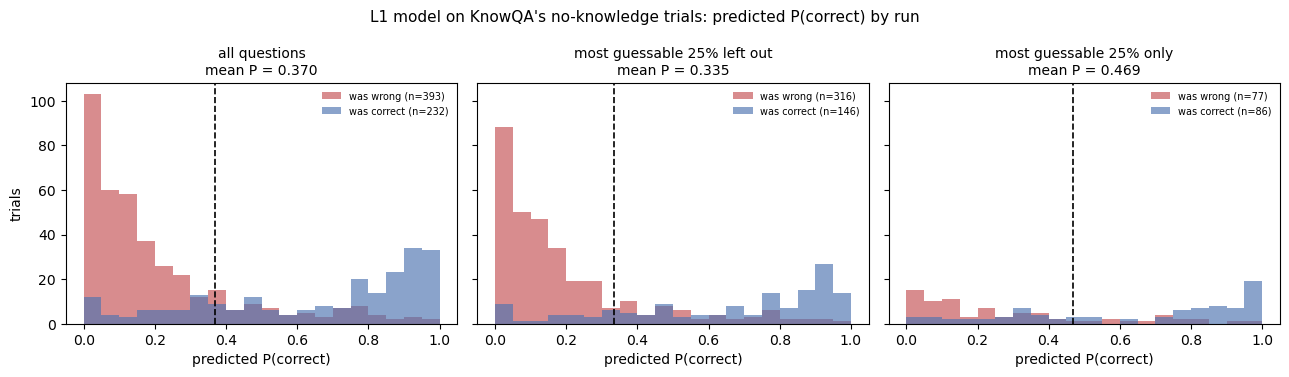

In [12]:
NK.plot_probability_histograms(runs, save=SAVE);

The confusion matrices, shaded by the share of each actual outcome, with the counts printed. Top left is the
specificity (wrong answers predicted wrong), bottom right the sensitivity (right answers predicted right).

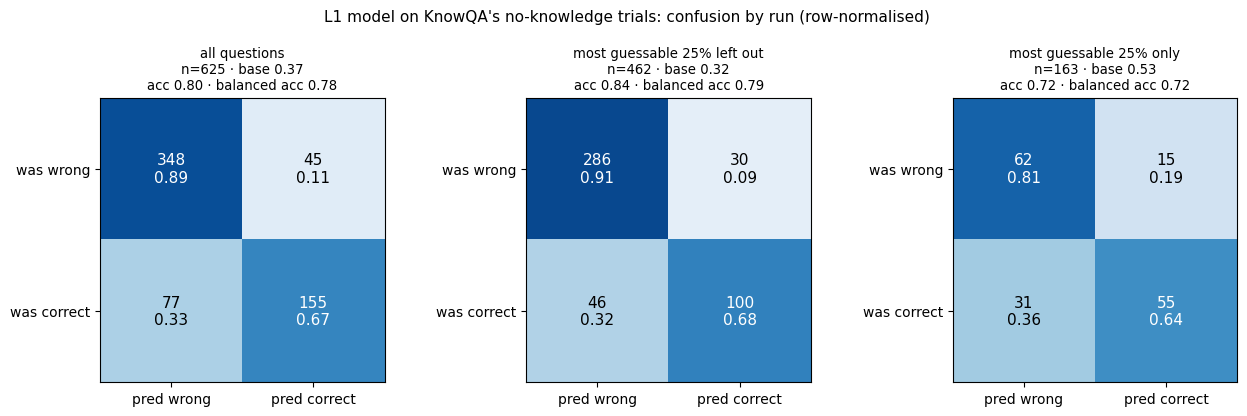

In [13]:
NK.plot_confusions(runs, save=SAVE);

Per participant and run: their accuracy, their mean confidence, the model's mean probability and its balanced
accuracy. Each person has about 48 no-knowledge trials, so the last column rests on about 12, and on few wrong or
few right answers: read it as a pattern, not a measurement.

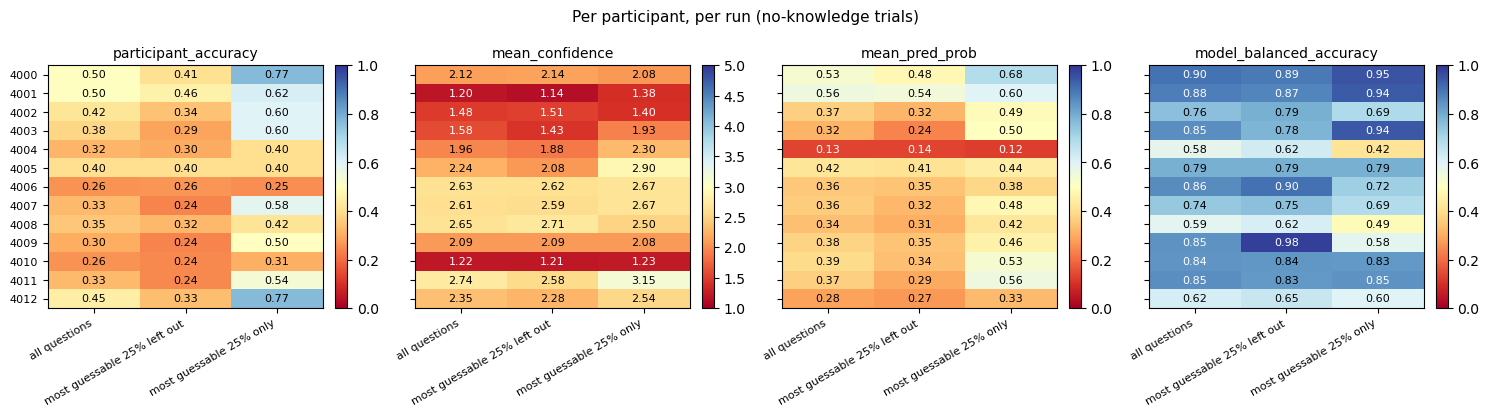

In [14]:
NK.plot_participant_heatmap(runs, save=SAVE);

## 5. Check: ranked without the experiment's own answers

The same ranking on `share_external`, the pooled share without KnowQA's answers, so the questions left out are
chosen without looking at the outcome the model is scored on. If the two rankings leave out nearly the same
questions and the scores barely move, the experiment's own answers in the pool do not matter.

In [15]:
flagged_ext, cut_ext = NK.flag_most_guessable(items, knowqa, top=TOP, share_col="share_external")
same = flagged.merge(flagged_ext[[QUESTION_KEY, "most_guessable"]], on=QUESTION_KEY, suffixes=("", "_ext"))
print(f"cut at {cut_ext:.3f}; {int(flagged_ext['most_guessable'].sum())} left out; "
      f"{int((same['most_guessable'] & same['most_guessable_ext']).sum())} left out by both rankings, "
      f"{int((same['most_guessable'] != same['most_guessable_ext']).sum())} by one only")
runs_ext = NK.run_frame(knowqa, flagged_ext, top=TOP)
display(NK.run_metrics(runs_ext).set_index("run").T.round(3))

cut at 0.500; 87 left out; 85 left out by both rankings, 5 by one only


run,all questions,most guessable 25% left out,most guessable 25% only
n,625,464,161
questions,337,250,87
n_correct,232,152,80
participant_accuracy,0.3712,0.327586,0.496894
model_accuracy,0.8048,0.836207,0.714286
balanced_accuracy,0.7768,0.79892,0.713735
sensitivity,0.668103,0.690789,0.625
specificity,0.885496,0.907051,0.802469
auc_model,0.866577,0.884151,0.81034
auc_confidence,0.517357,0.511798,0.508642


They do not: 85 questions are left out by both rankings, 5 by one only, and the AUC without the guessable
questions is 0.884 rather than 0.880.

## 6. Ranked on the experiment's own wording
*`no_knowledge.drop_edited_pilot`, `no_knowledge.unrankable`*

The same ranking and runs, with the pilot's guesses on reworded and rewritten questions taken out of the pool:
section 3 showed that their guessability barely carries over to the experiment's version. The pilot's guesses on
questions that stayed almost the same (identical, or one or two words changed) stay, as does every guess from
`guess.tsv` and KnowQA.

Three things change with it:

* **Some questions are left with nothing to rank them on.** `guess.tsv` covers only the first two batches, so a
  third-batch question whose pilot version was edited has no guesses outside KnowQA's own answers. Ranking it on
  those would rank it on the outcome the model is scored on, so `flag_most_guessable` refuses. **These questions
  are left out of all three runs here, the baseline included**, so the `all questions` run below is not section
  4's.
* **The guesses per question become uneven.** A question kept from the pilot has about 38; one known only from
  `guess.tsv` has six, so its share moves in steps of a sixth and reaches the extremes by chance more easily.
* **KnowQA's own answers weigh more.** Two answers out of about eight guesses is a quarter of the pool, not a
  twentieth. Section 5's check is repeated below, and this time it matters.

pilot guesses dropped: 6,984 of 16,263


51 no-knowledge questions have no guesses outside KnowQA, 99 trials, all of them left out below; by batch: {'3': 51}
286 questions ranked; cut at a pooled share of 0.450: 73 left out (25.5%)


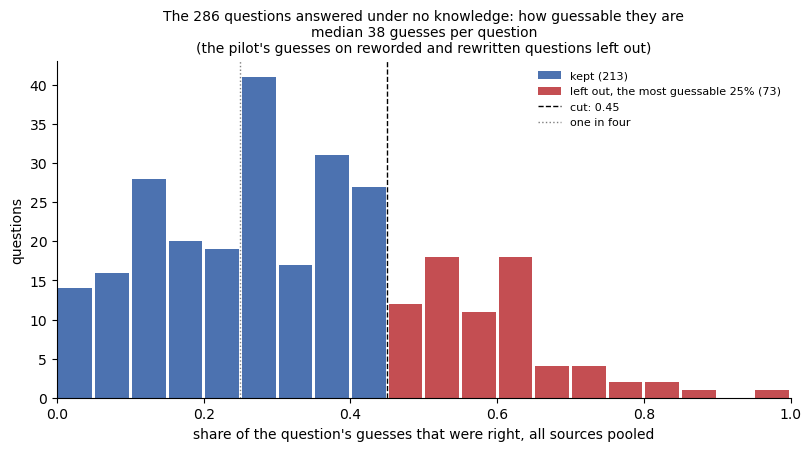

In [16]:
no_knowledge_trial = knowqa["regime"].eq(NK.NO_KNOWLEDGE)
guesses_fw = NK.drop_edited_pilot(guesses, pairs)
items_fw = NK.guessability(guesses_fw)
no_rank = NK.unrankable(items_fw, knowqa)
print(f"pilot guesses dropped: {len(guesses) - len(guesses_fw):,} of {int(guesses['dataset'].eq('pilot').sum()):,}")
print(f"{len(no_rank)} no-knowledge questions have no guesses outside KnowQA, "
      f"{int((no_knowledge_trial & knowqa[QUESTION_KEY].isin(no_rank)).sum())} trials, all of them left out below; "
      f"by batch: {no_rank.str[0].value_counts().to_dict()}")

knowqa_fw = knowqa[~knowqa[QUESTION_KEY].isin(no_rank)]
flagged_fw, cut_fw = NK.flag_most_guessable(items_fw, knowqa_fw, top=TOP)
n_out = int(flagged_fw["most_guessable"].sum())
print(f"{len(flagged_fw)} questions ranked; cut at a pooled share of {cut_fw:.3f}: "
      f"{n_out} left out ({n_out / len(flagged_fw):.1%})")
NK.plot_guessability(flagged_fw, cut_fw, top=TOP, pool="final_wording", save=SAVE);

Where each ranked question's outside guesses come from, and how often each kind is left out. If the six-guess
questions known only from `guess.tsv` were left out much more often than the rest, the ranking would be picking
up noise; then, which questions this ranking and section 3's agree on.

In [17]:
coverage = (flagged_fw["n_pilot"].gt(0).map({True: "pilot", False: "no pilot"}) + " + "
            + flagged_fw["n_guess"].gt(0).map({True: "guess.tsv", False: "no guess.tsv"})).rename("guessed in")
tab = pd.crosstab(coverage, flagged_fw["most_guessable"])
tab.columns = ["kept", "left_out"]
tab["share_left_out"] = tab["left_out"] / tab.sum(axis=1)
tab["median_outside_guesses"] = flagged_fw.groupby(coverage)["n_external"].median()
display(tab.round(3))
both = flagged_fw.merge(flagged[[QUESTION_KEY, "most_guessable"]], on=QUESTION_KEY, suffixes=("", "_sec3"))
print(f"of the {len(both)} questions in both rankings, {int((both['most_guessable'] & both['most_guessable_sec3']).sum())} "
      f"are left out by both and {int((both['most_guessable'] != both['most_guessable_sec3']).sum())} by one only")

,kept,left_out,share_left_out,median_outside_guesses
guessed in,,,,
no pilot + guess.tsv,66,28,0.298,6.0
pilot + guess.tsv,97,32,0.248,37.0
pilot + no guess.tsv,50,13,0.206,39.0


of the 286 questions in both rankings, 46 are left out by both and 41 by one only


In [18]:
runs_fw = NK.run_frame(knowqa_fw, flagged_fw, top=TOP)
display(NK.run_metrics(runs_fw).set_index("run").T.round(3))

run,all questions,most guessable 25% left out,most guessable 25% only
n,526,391,135
questions,286,213,73
n_correct,186,104,82
participant_accuracy,0.353612,0.265985,0.607407
model_accuracy,0.821293,0.84399,0.755556
balanced_accuracy,0.783839,0.783369,0.782098
sensitivity,0.655914,0.653846,0.658537
specificity,0.911765,0.912892,0.90566
auc_model,0.876708,0.872085,0.873217
auc_confidence,0.526747,0.495058,0.579383


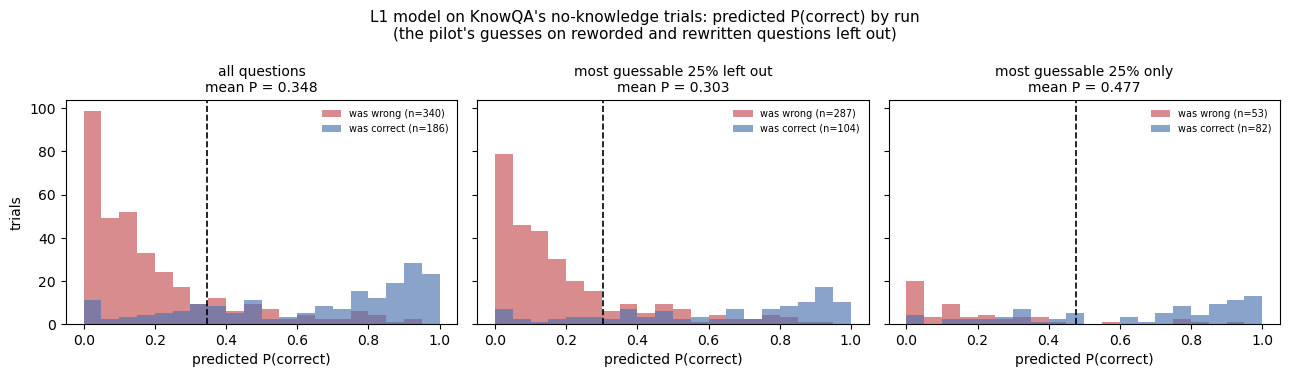

In [19]:
NK.plot_probability_histograms(runs_fw, pool="final_wording", save=SAVE);

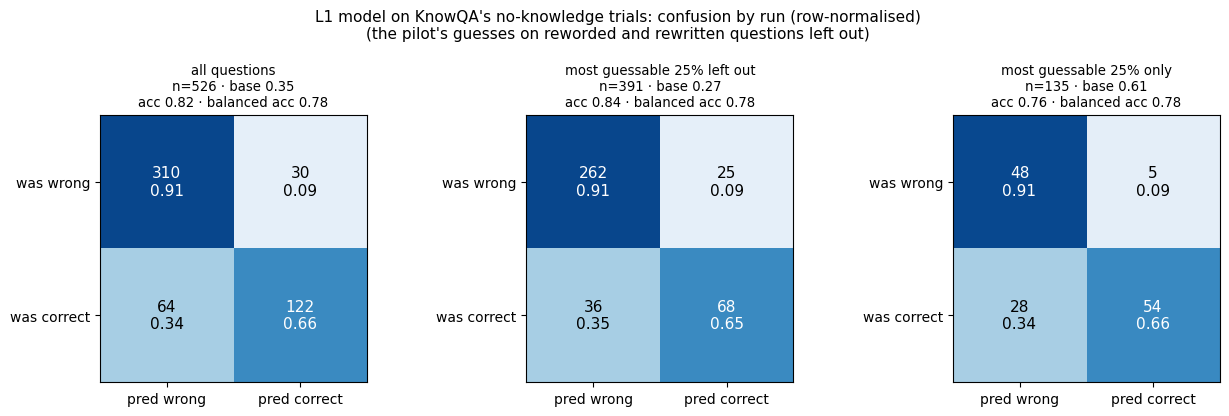

In [20]:
NK.plot_confusions(runs_fw, pool="final_wording", save=SAVE);

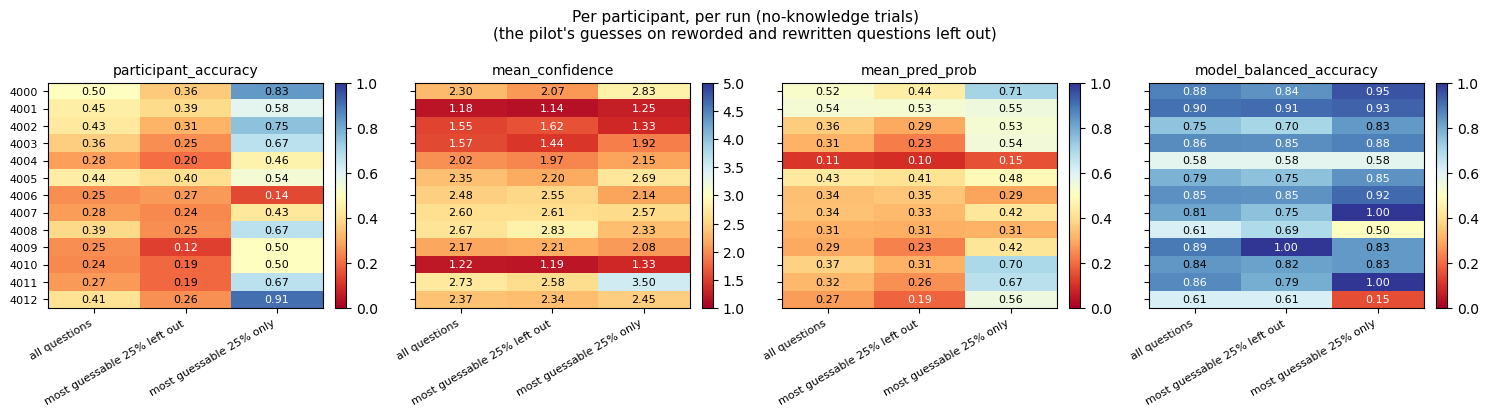

In [21]:
NK.plot_participant_heatmap(runs_fw, pool="final_wording", save=SAVE);

**Ranked this way, leaving out the guessable quarter changes nothing for the model**: AUC 0.877 on all the
rankable questions, 0.872 without the quarter and 0.873 on it alone, and a balanced accuracy of 0.78 in all three.
What it changes is how often the participants were right: 0.27 without the quarter, close to chance, and 0.61
on it.

But this ranking leans on the outcome. Ranked on outside guesses only (below), the two rankings disagree on 14 questions, the
participants' accuracy on the quarter left out falls from 0.61 to 0.53, and the model's picture returns to section
4's direction: AUC 0.884 without the quarter and 0.862 on it alone. So in this version KnowQA's own answers do
matter, and **the outside-only ranking is the one to read**.

In [22]:
flagged_fw_ext, cut_fw_ext = NK.flag_most_guessable(items_fw, knowqa_fw, top=TOP, share_col="share_external")
same = flagged_fw.merge(flagged_fw_ext[[QUESTION_KEY, "most_guessable"]], on=QUESTION_KEY, suffixes=("", "_ext"))
print(f"cut at {cut_fw_ext:.3f}; {int(flagged_fw_ext['most_guessable'].sum())} left out; "
      f"{int((same['most_guessable'] & same['most_guessable_ext']).sum())} left out by both rankings, "
      f"{int((same['most_guessable'] != same['most_guessable_ext']).sum())} by one only")
display(NK.run_metrics(NK.run_frame(knowqa_fw, flagged_fw_ext, top=TOP)).set_index("run").T.round(3))

cut at 0.457; 73 left out; 66 left out by both rankings, 14 by one only


run,all questions,most guessable 25% left out,most guessable 25% only
n,526,393,133
questions,286,213,73
n_correct,186,116,70
participant_accuracy,0.353612,0.295165,0.526316
model_accuracy,0.821293,0.847328,0.744361
balanced_accuracy,0.783839,0.801506,0.752381
sensitivity,0.655914,0.689655,0.6
specificity,0.911765,0.913357,0.904762
auc_model,0.876708,0.884041,0.862132
auc_confidence,0.526747,0.50389,0.570181


### Dropping the rewritten questions only

"The most edited" could also mean the rewritten questions alone, keeping the pilot's guesses on the reworded
ones. Fewer questions are left unrankable then. The same runs, ranked both ways.

In [23]:
keep = ("identical", "1-2 words", "reworded")
items_rw = NK.guessability(NK.drop_edited_pilot(guesses, pairs, keep=keep))
no_rank_rw = NK.unrankable(items_rw, knowqa)
knowqa_rw = knowqa[~knowqa[QUESTION_KEY].isin(no_rank_rw)]
print(f"{len(no_rank_rw)} questions unrankable "
      f"({int((no_knowledge_trial & knowqa[QUESTION_KEY].isin(no_rank_rw)).sum())} trials), left out")
rows = []
for col in ["share_correct", "share_external"]:
    fl, _ = NK.flag_most_guessable(items_rw, knowqa_rw, top=TOP, share_col=col)
    rows.append(NK.run_metrics(NK.run_frame(knowqa_rw, fl, top=TOP)).assign(ranked_on=col))
display(pd.concat(rows)[["ranked_on", "run", "n", "questions", "participant_accuracy", "balanced_accuracy",
                         "auc_model", "auc_confidence"]].round(3).reset_index(drop=True))

40 questions unrankable (78 trials), left out


,ranked_on,run,n,questions,participant_accuracy,balanced_accuracy,auc_model,auc_confidence
0,share_correct,all questions,547,297,0.355,0.786,0.878,0.524
1,share_correct,most guessable 25% left out,409,222,0.271,0.797,0.881,0.481
2,share_correct,most guessable 25% only,138,75,0.601,0.765,0.875,0.610
3,share_external,all questions,547,297,0.355,0.786,0.878,0.524
4,share_external,most guessable 25% left out,411,222,0.297,0.812,0.890,0.486
5,share_external,most guessable 25% only,136,75,0.529,0.737,0.862,0.613


The same picture: ranked with KnowQA's answers in the pool, no difference for the model; ranked on outside
guesses only, a little better without the guessable quarter (AUC 0.890) and a little worse on it (0.862).

## 7. What it shows

The numbers below are from KnowQA's 13 participants and 625 no-knowledge trials, on 337 questions.

**How much the pilot differs from the experiment's version** (section 2). `guess.tsv` is the experiment's version:
310 of its 324 questions are identical, 13 differ by one or two words, and no answer key differs. The pilot
differs much more. Of its 486 questions, 205 are identical and 72 differ by one or two words, so 277 (57%) are
almost the same. Another 63 are reworded and 146 rewritten, in at least one text more than half new, most often
a wrong answer. One answer key changed (`2_3_4_1`).

**Guessability carries over only where the question stayed the same** (section 3). Between the pilot and
`guess.tsv`, the per-question share right agrees at Spearman 0.47 for identical questions and 0.62 for one- or
two-word edits, but 0.02 for reworded and 0.24 for rewritten ones. The rewritten questions were the easy ones in
the pilot (0.45 right, against 0.35 for identical ones) and much less so in the experiment's version (0.35). That
suggests the pilot was used to fix questions that gave their answer away; this is an inference.

**The drastic ranking** (sections 3 to 5). Pooled, a no-knowledge question has a median of 39 guesses, 32 of them
from the pilot. The cut falls at a share of 0.50 right and leaves out 88 of the 337 questions (26%). The sources
agree only moderately on which questions are guessable (`guess.tsv` against the pilot, Spearman 0.39; KnowQA
against either, about 0.28), so the pooled share is mostly the pilot's. 47 of the 88 are rewritten pilot
questions: half of all rewritten questions are left out, against 15% of identical ones. So about half of what it
leaves out was chosen on a pilot version that the experiment's participants never saw. Without the 88, the
model's AUC rises from 0.867 to 0.880 and its balanced accuracy from 0.777 to 0.795; on the 88 alone it does worse
(AUC 0.817). Ranking without KnowQA's own answers changes little here (AUC 0.884 without the quarter).

**Ranked on the experiment's own wording** (section 6). Without the pilot's guesses on reworded and rewritten
questions, 51 third-batch questions (99 trials) have no guesses outside KnowQA and are left out of every run; the
model's AUC on the 286 left is already 0.877. KnowQA's own answers now weigh much more in the pool, and they
matter: with them in, leaving out the guessable quarter changes nothing for the model (AUC 0.877, 0.872, 0.873).
Ranked on outside guesses only, it goes the same way as the drastic ranking, more weakly: 0.884 without the
quarter and 0.862 on it, against 0.817 there. Dropping only the rewritten questions gives the same picture.

**Across all the rankings that do not use the outcome**: leaving out the most guessable quarter raises the AUC to
about 0.88 to 0.89 and lowers the participants' share right by four to six points, to about 0.30 to 0.33, closer to chance.
The model does somewhat worse on the guessable questions themselves (AUC 0.81 to 0.86), mostly by giving their
wrong answers higher probabilities in the drastic ranking. The differences are small against the size of the
runs (about 130 to 160 trials on the guessable quarter), and nothing here tests them. The participants'
confidence rating stays near chance throughout.

**Choices made here, any of which could go the other way:**

* in sections 3 to 5, the pilot is pooled whatever its changes, including the one changed answer key; in section
  6, only its almost-unchanged questions are;
* in section 6, the questions left with no outside guesses are left out of every run, rather than ranked on the
  pilot after all or on KnowQA's answers alone;
* pilot guesses made after reading earlier paragraphs of the article are kept;
* Ele and Adv are pooled;
* KnowQA's own answers are in the pool of the main rankings, with an outside-only ranking as the check;
* the shares are raw: a question with six guesses is ranked like one with forty;
* the questions are left out of the test only, not of the L1 training trials;
* the quarter is of the rankable no-knowledge questions, with ties at the cut left out too.